# 10 · Task planning

Let the robot work out the order of its actions: describe actions in PDDL, ground them, and search — with the
C++ parser, grounder and planners.

In [1]:
# Installs the module when it is missing (e.g. on Colab); a local `pip install -e .` is used as is.
import importlib.util

if importlib.util.find_spec("motion_planning") is None:
    %pip install -q git+https://github.com/Rudip1/learn-motion-planning

## Recap

Theory: [`1_theory/10_task_planning.md`](../../1_theory/10_task_planning.md).

- A state is the set of true facts (10.1); an action has a precondition, an add list and a delete list (10.2).
- Applicable if $\mathrm{pre}^+ \subseteq s$ and $\mathrm{pre}^- \cap s = \emptyset$ (10.3); progression
  $s' = (s \setminus \mathrm{del}) \cup \mathrm{add}$ (10.4).
- PDDL writes action *schemas*; grounding instantiates them, pruning by static facts.
- Search: breadth-first (optimal length), A* with $f = g + wh$ (10.5), greedy with $f = h$ (10.6).
- Heuristics: goal count (10.7); delete relaxation (10.8) gives $h_{max}$ (admissible, 10.9) and $h_{add}$
  (informative, 10.10).

In [2]:
import matplotlib.pyplot as plt
import numpy as np

from motion_planning import task
from motion_planning.plotting import SERIES, use_style

use_style()
BFS, ASTAR, GREEDY = task.SearchAlgorithm.BreadthFirst, task.SearchAlgorithm.AStar, task.SearchAlgorithm.GreedyBestFirst
H = task.Heuristic

## A domain and a problem

The pick-and-place domain: a mobile manipulator with one suction gripper moves boxes between stands.

In [3]:
print(task.example("pick_place_domain"))
print(task.example("pick_place_swap"))

; A mobile manipulator with one suction gripper moves boxes between stands at different places (the task layer
; of the pick-and-place robot in vehicle-manipulator-task-priority). Typed, with a negative precondition: a box can
; be put only on a free stand.
(define (domain pick-place)
  (:requirements :strips :typing :negative-preconditions)
  (:types place stand box)
  (:predicates (robot-at ?p - place) (stand-at ?s - stand ?p - place) (on ?b - box ?s - stand)
               (occupied ?s - stand) (holding ?b - box) (gripper-free) (connected ?from ?to - place))
  (:action drive
    :parameters (?from ?to - place)
    :precondition (and (robot-at ?from) (connected ?from ?to))
    :effect (and (robot-at ?to) (not (robot-at ?from))))
  (:action pick
    :parameters (?b - box ?s - stand ?p - place)
    :precondition (and (robot-at ?p) (stand-at ?s ?p) (on ?b ?s) (gripper-free))
    :effect (and (holding ?b) (not (on ?b ?s)) (not (occupied ?s)) (not (gripper-free))))
  (:action place
    :p

In [4]:
domain, problem, t = task.load_example("pick_place_domain", "pick_place_swap")
print(f"{len(t.facts)} fluent facts, {len(t.actions)} ground actions")
print("initial state:", t.describe(t.init))
for a in t.actions[:6]:
    print(" ", a.name, "pre:", [t.facts[f] for f in a.pre], "not:", [t.facts[f] for f in a.pre_neg])

15 fluent facts, 16 ground actions
initial state: (gripper-free) (occupied s1) (occupied s2) (on blue s2) (on red s1) (robot-at corridor)
  (drive corridor room1) pre: ['(robot-at corridor)'] not: []
  (drive corridor room2) pre: ['(robot-at corridor)'] not: []
  (drive room1 corridor) pre: ['(robot-at room1)'] not: []
  (drive room2 corridor) pre: ['(robot-at room2)'] not: []
  (pick blue s1 room1) pre: ['(robot-at room1)', '(on blue s1)', '(gripper-free)'] not: []
  (pick blue s2 room2) pre: ['(robot-at room2)', '(on blue s2)', '(gripper-free)'] not: []


In [5]:
r = task.plan(t, task.SearchConfig(BFS, H.Zero))
for k, name in enumerate(task.plan_names(t, r.plan), 1):
    print(f"{k:2d}. {name}")
print("valid:", task.validate_plan(t, r.plan) == "", " expanded:", r.expanded)

 1. (drive corridor room1)
 2. (pick red s1 room1)
 3. (drive room1 corridor)
 4. (place red s3 corridor)
 5. (drive corridor room2)
 6. (pick blue s2 room2)
 7. (drive room2 corridor)
 8. (drive corridor room1)
 9. (place blue s1 room1)
10. (drive room1 corridor)
11. (pick red s3 corridor)
12. (drive corridor room2)
13. (place red s2 room2)
valid: True  expanded: 31


## ✏️ Exercise 1 — progression by hand

Implement (10.3) and (10.4) on Python sets of fact *names*. Use them to replay the plan above and check that the
final state satisfies the goal.

In [6]:
def applicable_set(action, s):
    return all(t.facts[f] in s for f in action.pre) and not any(t.facts[f] in s for f in action.pre_neg)


def progress(action, s):
    return (s - {t.facts[f] for f in action.delete}) | {t.facts[f] for f in action.add}

In [7]:
s = set(t.true_facts(t.init))
for i in r.plan:
    a = t.actions[i]
    assert applicable_set(a, s)
    s = progress(a, s)
assert {"(on red s2)", "(on blue s1)"} <= s
states = task.plan_states(t, r.plan)
assert s == set(t.true_facts(states[-1]))
print("✓ progression")

✓ progression


## ✏️ Exercise 2 — how much does grounding prune?

The Gripper domain is untyped: `move` has 2 parameters, `pick` and `drop` have 3. With $n$ balls, two rooms and
two grippers there are $n + 4$ objects. How many bindings would grounding produce without pruning? Compare with
the actual number of ground actions.

In [8]:
def bindings(n):
    k = n + 4
    return k**2 + 2 * k**3

In [9]:
for n in (2, 4, 6, 8, 10):
    _, _, g = task.load_example("gripper_domain", f"gripper_n{n}")
    print(f"n = {n:2d}: {bindings(n):5d} bindings, {len(g.actions):3d} ground actions")
    assert len(g.actions) == 4 + 8 * n and bindings(n) == (n + 4) ** 2 + 2 * (n + 4) ** 3
print("✓ bindings")

n =  2:   468 bindings,  20 ground actions
n =  4:  1088 bindings,  36 ground actions
n =  6:  2100 bindings,  52 ground actions
n =  8:  3600 bindings,  68 ground actions
n = 10:  5684 bindings,  84 ground actions
✓ bindings


## ✏️ Exercise 3 — the relaxed cost $h_{max}$

Implement (10.8)–(10.9): iterate until no fact cost decreases; facts true in `s` cost 0; an action's cost is 1
plus the **max** of its precondition costs. Return `inf` when a goal fact stays unreachable.

In [10]:
def h_max(task_, s):
    cost = {f: (0.0 if s.test(f) else np.inf) for f in range(len(task_.facts))}
    changed = True
    while changed:
        changed = False
        for a in task_.actions:
            c = max((cost[p] for p in a.pre), default=0.0)
            if c == np.inf:
                continue
            for f in a.add:
                if c + a.cost < cost[f]:
                    cost[f] = c + a.cost
                    changed = True
    return max((cost[g] for g in task_.goal_pos), default=0.0)

In [11]:
for dom, prob in [("blocksworld_domain", "blocksworld_sussman"), ("blocksworld_domain", "blocksworld_reverse5"),
                  ("gripper_domain", "gripper_n4"), ("pick_place_domain", "pick_place_swap")]:
    _, _, g = task.load_example(dom, prob)
    for st in task.plan_states(g, task.plan(g, task.SearchConfig(GREEDY, H.HAdd)).plan):
        assert h_max(g, st) == task.heuristic(g, st, H.HMax)
print("✓ h_max")

✓ h_max


## Heuristics at work: Gripper

Five planners on Gripper with 2 to 8 balls (the figure of section 10.6 goes to 10).

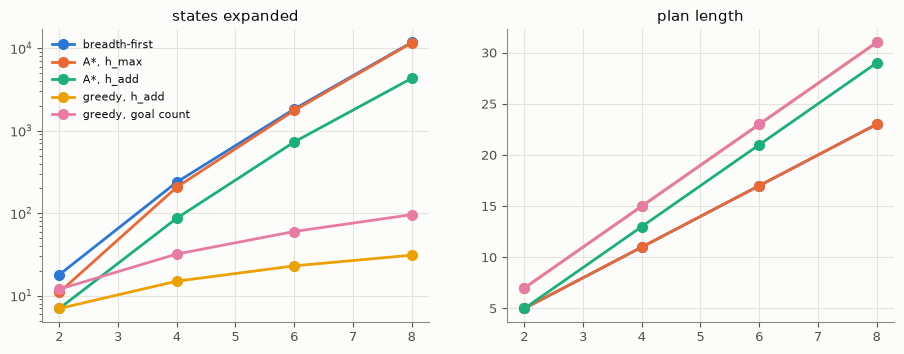

In [12]:
planners = [("breadth-first", BFS, H.Zero), ("A*, h_max", ASTAR, H.HMax), ("A*, h_add", ASTAR, H.HAdd),
            ("greedy, h_add", GREEDY, H.HAdd), ("greedy, goal count", GREEDY, H.GoalCount)]
ns = [2, 4, 6, 8]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for k, (name, alg, h) in enumerate(planners):
    res = [task.plan(task.load_example("gripper_domain", f"gripper_n{n}")[2], task.SearchConfig(alg, h)) for n in ns]
    ax[0].semilogy(ns, [x.expanded for x in res], "o-", color=SERIES[k], label=name)
    ax[1].plot(ns, [x.cost for x in res], "o-", color=SERIES[k], label=name)
ax[0].set_title("states expanded"); ax[1].set_title("plan length")
ax[0].legend(fontsize=8); plt.show()

## ✏️ Exercise 4 — a new action

Add a `push` action to the pick-and-place domain: the robot can push a box from a stand onto an adjacent free
stand **in the same place**, without the gripper (the gripper must be free). Write the PDDL text of the action and
check that, with two stands in one room, the planner moves a box in one step.

In [13]:
PUSH = """
  (:action push
    :parameters (?b - box ?from ?to - stand ?p - place)
    :precondition (and (robot-at ?p) (stand-at ?from ?p) (stand-at ?to ?p) (on ?b ?from) (not (occupied ?to))
                       (gripper-free))
    :effect (and (on ?b ?to) (occupied ?to) (not (on ?b ?from)) (not (occupied ?from))))"""

In [14]:
text = task.example("pick_place_domain").rstrip()
assert text.endswith(")")
dom_push = task.parse_domain(text[:-1] + PUSH + ")")
prob = task.parse_problem("""(define (problem shove) (:domain pick-place)
  (:objects room - place  s1 s2 - stand  red - box)
  (:init (robot-at room) (stand-at s1 room) (stand-at s2 room) (on red s1) (occupied s1) (gripper-free))
  (:goal (on red s2)))""")
gp = task.ground(dom_push, prob)
rp = task.plan(gp, task.SearchConfig(BFS, H.Zero))
print(task.plan_names(gp, rp.plan))
assert rp.solved and len(rp.plan) == 1 and "push" in task.plan_names(gp, rp.plan)[0]
print("✓ push")

['(push red s1 s2 room)']
✓ push


## 🔨 Break it — a forgotten delete effect

Remove `(not (robot-at ?from))` from `drive`. The robot is now "at" every place it has ever visited, and the
planner happily skips the drives back. The plan is valid in the broken model — and impossible for the robot.

In [15]:
broken = task.example("pick_place_domain").replace("(and (robot-at ?to) (not (robot-at ?from)))", "(robot-at ?to)")
assert broken != task.example("pick_place_domain")
gb = task.ground(task.parse_domain(broken), task.parse_problem(task.example("pick_place_swap")))
rb = task.plan(gb, task.SearchConfig(BFS, H.Zero))
print(len(rb.plan), "actions in the broken model:", task.plan_names(gb, rb.plan))
idx = {a.name: i for i, a in enumerate(t.actions)}
print("replayed in the real model:", task.validate_plan(t, [idx[n] for n in task.plan_names(gb, rb.plan)]))

8 actions in the broken model: ['(drive corridor room1)', '(drive corridor room2)', '(pick blue s2 room2)', '(place blue s3 corridor)', '(pick red s1 room1)', '(place red s2 room2)', '(pick blue s3 corridor)', '(place blue s1 room1)']
replayed in the real model: step 1: (drive corridor room2) is not applicable


## 🔨 Break it — an inadmissible heuristic in A*

A* is optimal only with an admissible $h$. With $h_{add}$ it returns longer plans on Gripper.

In [16]:
for n in (4, 6, 8):
    g = task.load_example("gripper_domain", f"gripper_n{n}")[2]
    a1 = task.plan(g, task.SearchConfig(ASTAR, H.HMax))
    a2 = task.plan(g, task.SearchConfig(ASTAR, H.HAdd))
    print(f"n = {n}: h_max {int(a1.cost)} actions ({a1.expanded} expanded)   h_add {int(a2.cost)} actions ({a2.expanded} expanded)")

n = 4: h_max 11 actions (207 expanded)   h_add 13 actions (87 expanded)
n = 6: h_max 17 actions (1759 expanded)   h_add 21 actions (730 expanded)
n = 8: h_max 23 actions (11615 expanded)   h_add 29 actions (4313 expanded)


## 🔨 Break it — blind search meets combinatorics

Breadth-first search on Blocksworld: reverse towers of growing height. The number of states explodes; a
heuristic keeps greedy search linear in the plan length.

In [17]:
def reverse_tower(k):
    blocks = [f"b{i}" for i in range(k)]
    init = " ".join(f"(on {blocks[i]} {blocks[i + 1]})" for i in range(k - 1))
    goal = " ".join(f"(on {blocks[i + 1]} {blocks[i]})" for i in range(k - 1))
    return task.parse_problem(f"""(define (problem rev{k}) (:domain blocksworld) (:objects {' '.join(blocks)})
      (:init {init} (ontable {blocks[-1]}) (clear {blocks[0]}) (handempty)) (:goal (and {goal})))""")


bw = task.parse_domain(task.example("blocksworld_domain"))
for k in range(3, 8):
    g = task.ground(bw, reverse_tower(k))
    b = task.plan(g, task.SearchConfig(BFS, H.Zero))
    gr = task.plan(g, task.SearchConfig(GREEDY, H.HAdd))
    print(f"{k} blocks: breadth-first {b.expanded:6d} expanded ({int(b.cost)} actions)   greedy h_add {gr.expanded:3d} expanded ({int(gr.cost)} actions)")

3 blocks: breadth-first      9 expanded (6 actions)   greedy h_add   6 expanded (6 actions)
4 blocks: breadth-first     27 expanded (8 actions)   greedy h_add   8 expanded (8 actions)
5 blocks: breadth-first     95 expanded (10 actions)   greedy h_add  10 expanded (10 actions)
6 blocks: breadth-first    384 expanded (12 actions)   greedy h_add  13 expanded (12 actions)
7 blocks: breadth-first   1727 expanded (14 actions)   greedy h_add  16 expanded (14 actions)


## What to remember

- STRIPS: states are sets of facts; actions add and delete facts; everything else stays (the frame assumption).
- PDDL schemas are grounded into actions; static facts prune most bindings.
- Breadth-first is optimal in length; A* is optimal with an admissible heuristic; greedy search is fast and not
  optimal.
- Delete relaxation gives $h_{max}$ (admissible, often weak) and $h_{add}$ (strong, overestimating).
- A plan is only as correct as the action model: one missing delete makes it fiction.